# 03 Parameter and model recovery (v1 figures 19 and 18)

Run the simulations outside the notebook (they take hours; every dataset is saved as soon as it is done, so a run can
be stopped and resumed):

    cd av_dur_experiment_v2
    python -m avdur_analysis.recovery --kind parameter --n 50
    python -m avdur_analysis.recovery --kind model --n 50

Each synthetic dataset reuses the stimuli and trial counts of a randomly chosen complete participant. Its parameters
come from group-level distributions of the real joint fits (`recovery.group_distribution`): σ log-normal, λ uniform on
0-0.06, probabilities logit-normal, each spread at least `SIGMA_SD_MIN` / `LOGIT_SD_MIN`, so they cover more than
the few fitted participants. Parameter recovery fits the generating model; model recovery fits all three and takes the
best AIC.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from avdur_analysis import data as D, fitting as F, models as M, psychometric as P, style as St
%matplotlib inline
St.setup(scale=0.8)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220, "display.max_columns", 40)
from avdur_analysis import recovery as RC

Distributions the parameters are drawn from (kind, centre, spread; log or logit scale):

In [2]:
pd.DataFrame([dict(model=m, parameter=k, kind=v[0], a=v[1], b=v[2]) for m in M.MODELS
              for k, v in RC.group_distribution(m).items()]).round(3)

,model,parameter,kind,a,b
0,fusion,lapse,uniform,0.000,0.060
1,fusion,sigma_a_low,lognormal,-1.527,0.250
2,fusion,sigma_a_high,lognormal,-0.927,0.431
3,fusion,sigma_v,lognormal,-0.425,0.250
4,causal,lapse,uniform,0.000,0.060
5,causal,sigma_a_low,lognormal,-1.454,0.254
6,causal,sigma_a_high,lognormal,-0.765,0.563
7,causal,sigma_v,lognormal,-0.863,0.473
8,causal,p_c,logitnormal,2.007,2.230
9,switching,lapse,uniform,0.000,0.060


## Figure 1: parameter recovery
Rows: generating model; columns: parameters. Dashed: identity; grey band: ±5%; inset: Pearson r and RMSE.

In [3]:
t = RC.parameter_table()
t.groupby(["model", "parameter"]).apply(lambda s: pd.Series(dict(n=len(s), r=s[["true", "recovered"]].corr().iloc[0, 1],
    rmse=((s.true - s.recovered) ** 2).mean() ** 0.5, bias=(s.recovered - s.true).mean()))).round(3)

/var/folders/_l/d96lf1k57sg3sgm171h4qx05_dn4td/T/ipykernel_99623/226937012.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t.groupby(["model", "parameter"]).apply(lambda s: pd.Series(dict(n=len(s), r=s[["true", "recovered"]].corr().iloc[0, 1],


n      r   rmse   bias
model  parameter                              
causal lapse         24.0  0.858  0.010  0.001
       p_c           24.0  0.968  0.080 -0.011
       sigma_a_high  24.0  0.968  0.100  0.029
       sigma_a_low   24.0  0.960  0.016  0.004
       sigma_v       24.0  0.929  0.059 -0.010
fusion lapse         50.0  0.743  0.014 -0.001
       sigma_a_high  50.0  0.959  0.050  0.003
       sigma_a_low   50.0  0.950  0.019 -0.004
       sigma_v       50.0  0.956  0.052 -0.004

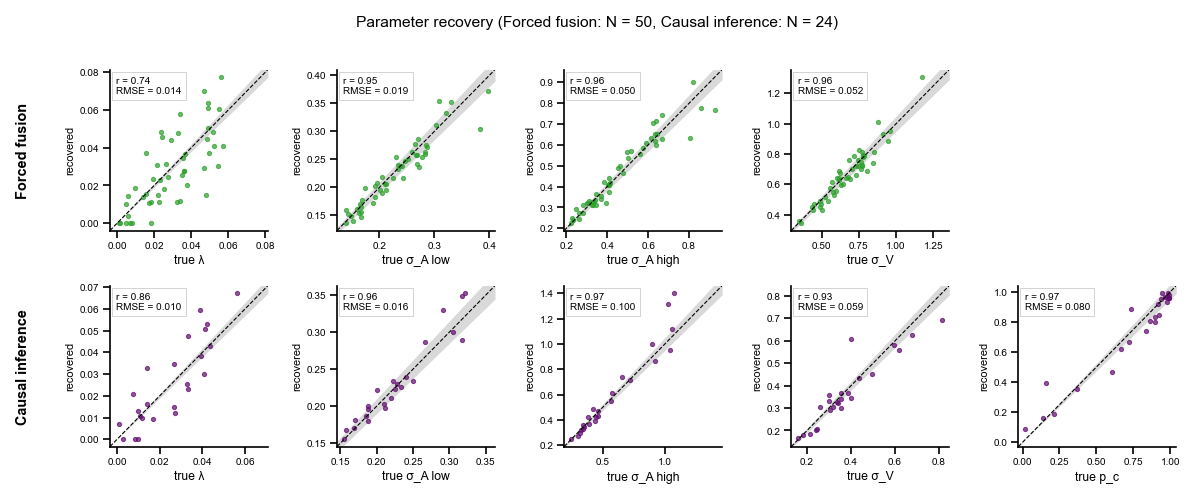

In [4]:
fig = RC.fig_parameter_recovery()
plt.show()

## Figure 2: model recovery (generating model × best model by AIC)

In [5]:
RC.confusion("aic")

""


In [6]:
fig = RC.fig_model_recovery("aic")
plt.show()

FileNotFoundError: no model-recovery results: python -m avdur_analysis.recovery --kind model

In [ ]:
fig = RC.fig_model_recovery("bic")
plt.show()